# Diabetes status classification — Neural network

DTU 02820 · Group 10 · Assignment 1

Run from the repository root in a fresh kernel, from top to bottom. Install the dependencies in `requirements.txt`; see `README.md` for setup and the report results.

The balanced BRFSS 2015 dataset classifies **reported prediabetes or diabetes status**, not future disease onset. Scores are not calibrated absolute risks for the general population. Explanations describe model behaviour, not causal effects or treatment advice.

Saved outputs are the original report run. Executing this notebook overwrites them locally; software versions and CPU/GPU execution can change results. New machine-readable results are written to `results/nn/`. Historical notebooks, including exploratory PFI/IG analyses, are in `archive/`.


In [1]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.metrics import (classification_report, confusion_matrix, ConfusionMatrixDisplay,
                             roc_auc_score, average_precision_score, RocCurveDisplay,
                             brier_score_loss)

DATA_PATH = Path('diabetes_binary_5050split_health_indicators_BRFSS2015.csv')
SEED = 42
if not DATA_PATH.is_file():
    raise FileNotFoundError(f'Set DATA_PATH to the CSV downloaded from DTU Learn: {DATA_PATH.resolve()}')
df = pd.read_csv(DATA_PATH)
target = 'Diabetes_binary'
if target not in df:
    raise KeyError(f'Missing {target}; columns: {df.columns.tolist()}')
if df.columns.duplicated().any():
    raise ValueError('Duplicate column names')
X = df.drop(columns=target).apply(pd.to_numeric, errors='raise')
y = df[target].astype(int)
assert set(y.unique()) == {0, 1}, 'Expected binary label 0/1'
print('Rows, features:', X.shape, '| positive fraction:', round(y.mean(), 3))
print('Missing values:', int(X.isna().sum().sum()))
display(X.head())

# Identical split in both notebooks. Split before fitting any imputation/scaling.
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, stratify=y, random_state=SEED)
features = X.columns.tolist()

from IPython.display import display


Rows, features: (70692, 21) | positive fraction: 0.5
Missing values: 0


,HighBP,HighChol,CholCheck,BMI,Smoker,Stroke,HeartDiseaseorAttack,PhysActivity,Fruits,Veggies,...,AnyHealthcare,NoDocbcCost,GenHlth,MentHlth,PhysHlth,DiffWalk,Sex,Age,Education,Income
0,1.0,0.0,1.0,26.0,0.0,0.0,0.0,1.0,0.0,1.0,...,1.0,0.0,3.0,5.0,30.0,0.0,1.0,4.0,6.0,8.0
1,1.0,1.0,1.0,26.0,1.0,1.0,0.0,0.0,1.0,0.0,...,1.0,0.0,3.0,0.0,0.0,0.0,1.0,12.0,6.0,8.0
2,0.0,0.0,1.0,26.0,0.0,0.0,0.0,1.0,1.0,1.0,...,1.0,0.0,1.0,0.0,10.0,0.0,1.0,13.0,6.0,8.0
3,1.0,1.0,1.0,28.0,1.0,0.0,0.0,1.0,1.0,1.0,...,1.0,0.0,3.0,0.0,3.0,0.0,1.0,11.0,6.0,8.0
4,0.0,0.0,1.0,29.0,1.0,0.0,0.0,1.0,1.0,1.0,...,1.0,0.0,2.0,0.0,0.0,0.0,0.0,8.0,5.0,8.0


## Our patient: shared test respondent

Both notebooks explain **original zero-based CSV index 57608**, not a personal identifier. Keep the original CSV row order. The assertions below ensure this respondent belongs to the held-out test set. The table shows raw inputs, before preprocessing. Global SHAP uses a separate random sample of 40 test respondents.


In [2]:
# Use the SAME original CSV row in both notebooks.
# Requires the same CSV file and row order; this is an index, not a personal ID.
EXPLAIN_INDEX = 57608
if not X.index.is_unique:
    raise ValueError("Dataset index must be unique.")
if EXPLAIN_INDEX not in X_test.index:
    raise ValueError(f"Index {EXPLAIN_INDEX} is not in the test set. Check CSV and split.")
assert EXPLAIN_INDEX not in X_train.index
explain_row = X_test.loc[[EXPLAIN_INDEX]].copy()
row_position = X_test.index.get_loc(EXPLAIN_INDEX)

print("Original dataset index:", EXPLAIN_INDEX)
print("Position in test set:", row_position)
print("True survey label:", int(y_test.loc[EXPLAIN_INDEX]))
display(explain_row.T.rename(columns={EXPLAIN_INDEX: "Raw feature value"})
        .rename_axis("Feature"))


Original dataset index: 57608
Position in test set: 0
True survey label: 1


,Raw feature value
Feature,
HighBP,1.0
HighChol,1.0
CholCheck,1.0
BMI,53.0
Smoker,0.0
Stroke,0.0
HeartDiseaseorAttack,0.0
PhysActivity,0.0
Fruits,0.0


## Preprocessing and training

The report run fits median imputation and standardization on the outer training set, then splits that transformed set into fitting and validation subsets. The held-out test set remains separate, but validation rows influence preprocessing statistics. This is a limitation of validation, not a leak from the test set. The original procedure is retained to document the report; a future experiment should split before fitting preprocessing and report new results.

The network has 21 inputs, 32 ReLU hidden units and one output logit. BCEWithLogitsLoss includes the sigmoid in a numerically stable loss. Thirty epochs are fixed; no early stopping was performed.


Device: cuda | final validation loss: 0.5021


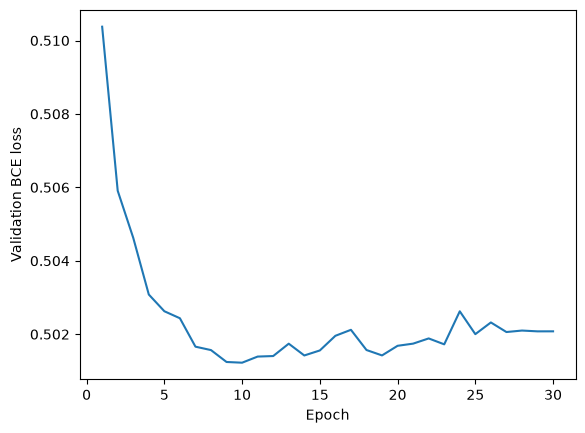

In [3]:
import torch
from torch import nn
from torch.utils.data import TensorDataset, DataLoader
from sklearn.pipeline import make_pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler

torch.manual_seed(SEED)
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
preprocess = make_pipeline(SimpleImputer(strategy='median'), StandardScaler())
Z_train = preprocess.fit_transform(X_train).astype('float32')
Z_test = preprocess.transform(X_test).astype('float32')
# Validation comes exclusively from the training portion, with the same seed.
Z_fit, Z_val, y_fit, y_val = train_test_split(
    Z_train, y_train.to_numpy(), test_size=0.20,
    stratify=y_train, random_state=SEED)
loader = DataLoader(TensorDataset(torch.from_numpy(Z_fit),
                                  torch.from_numpy(y_fit.astype('float32'))),
                    batch_size=256, shuffle=True)
net = nn.Sequential(nn.Linear(len(features), 32), nn.ReLU(), nn.Linear(32, 1)).to(device)
optimizer = torch.optim.Adam(net.parameters(), lr=1e-3, weight_decay=1e-4)
loss_fn = nn.BCEWithLogitsLoss()
history = []
for epoch in range(30):
    net.train()
    for xb, yb in loader:
        optimizer.zero_grad()
        loss = loss_fn(net(xb.to(device)).squeeze(1), yb.to(device))
        loss.backward()
        optimizer.step()
    net.eval()
    with torch.no_grad():
        val_logits = net(torch.from_numpy(Z_val).to(device)).squeeze(1)
        val_loss = loss_fn(val_logits, torch.from_numpy(y_val.astype('float32')).to(device)).item()
    history.append(val_loss)
print('Device:', device, '| final validation loss:', round(history[-1], 4))
plt.plot(range(1, len(history)+1), history)
plt.xlabel('Epoch'); plt.ylabel('Validation BCE loss'); plt.show()


## Held-out evaluation

The fixed 30 epochs are an illustrative baseline. Choose any tuning or early stopping using validation data only.

                  precision    recall  f1-score   support

no (pre)diabetes       0.78      0.70      0.74      7070
   (pre)diabetes       0.73      0.80      0.76      7069

        accuracy                           0.75     14139
       macro avg       0.75      0.75      0.75     14139
    weighted avg       0.75      0.75      0.75     14139

ROC AUC: 0.830
Average precision: 0.805
Brier score (balanced sample only): 0.167


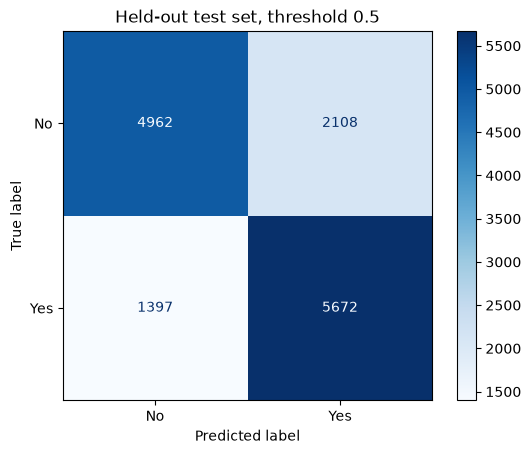

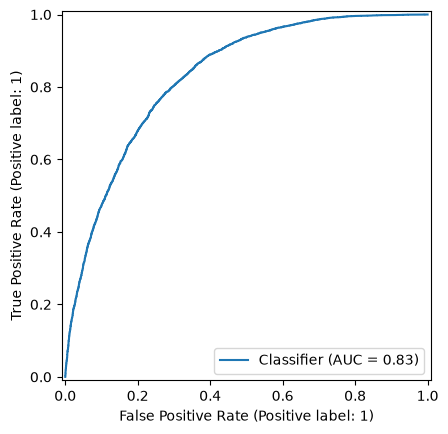

In [4]:
net.eval()
with torch.no_grad():
    probabilities = torch.sigmoid(net(torch.from_numpy(Z_test).to(device))).cpu().numpy().ravel()
def evaluate(y_true, probability, threshold=0.5):
    prediction = (probability >= threshold).astype(int)
    print(classification_report(y_true, prediction, target_names=['no (pre)diabetes', '(pre)diabetes']))
    print(f'ROC AUC: {roc_auc_score(y_true, probability):.3f}')
    print(f'Average precision: {average_precision_score(y_true, probability):.3f}')
    print(f'Brier score (balanced sample only): {brier_score_loss(y_true, probability):.3f}')
    ConfusionMatrixDisplay.from_predictions(y_true, prediction, display_labels=['No', 'Yes'], cmap='Blues')
    plt.title('Held-out test set, threshold 0.5'); plt.show()
    RocCurveDisplay.from_predictions(y_true, probability); plt.show()

evaluate(y_test, probabilities)


## Prediction interface for LIME and SHAP

Both explainers receive raw feature values. The wrapper restores column names, applies the fitted preprocessing and returns scores for classes 0 and 1.


In [5]:
from sklearn.base import BaseEstimator, ClassifierMixin

class NetworkClassifier(ClassifierMixin, BaseEstimator):
    def __init__(self):
        self.classes_ = np.array([0, 1])

    def fit(self, X=None, y=None):
        # The network and preprocessing are already trained.
        return self

    def predict_proba(self, X_input):
        frame = pd.DataFrame(np.asarray(X_input), columns=features)
        z = preprocess.transform(frame).astype('float32')
        net.eval()
        with torch.no_grad():
            p = torch.sigmoid(
                net(torch.from_numpy(z).to(device))
            ).cpu().numpy().ravel()
        return np.column_stack([1 - p, p])

model = NetworkClassifier()


## Error audit

In [7]:
audit = X_test.copy()
audit['actual'] = y_test
audit['score'] = probabilities
audit['predicted'] = (probabilities >= 0.5).astype(int)
display(audit.loc[(audit.actual == 1) & (audit.predicted == 0)].sort_values('score').head(10))
display(audit.loc[(audit.actual == 0) & (audit.predicted == 1)].sort_values('score', ascending=False).head(10))


,HighBP,HighChol,CholCheck,BMI,Smoker,Stroke,HeartDiseaseorAttack,PhysActivity,Fruits,Veggies,...,MentHlth,PhysHlth,DiffWalk,Sex,Age,Education,Income,actual,score,predicted
66055,0.0,0.0,1.0,20.0,0.0,0.0,0.0,1.0,1.0,1.0,...,0.0,0.0,0.0,1.0,2.0,6.0,7.0,1,0.006861,0
51216,0.0,0.0,1.0,24.0,1.0,0.0,0.0,1.0,0.0,1.0,...,5.0,1.0,0.0,0.0,3.0,6.0,5.0,1,0.011638,0
41488,0.0,0.0,1.0,26.0,1.0,0.0,0.0,1.0,0.0,1.0,...,0.0,0.0,0.0,0.0,3.0,5.0,6.0,1,0.014535,0
67194,0.0,0.0,1.0,24.0,0.0,0.0,0.0,1.0,1.0,1.0,...,20.0,1.0,0.0,1.0,3.0,6.0,8.0,1,0.019323,0
41386,0.0,0.0,1.0,22.0,0.0,0.0,0.0,1.0,1.0,1.0,...,0.0,0.0,0.0,1.0,2.0,5.0,8.0,1,0.020838,0
49746,0.0,0.0,1.0,22.0,0.0,0.0,0.0,1.0,1.0,1.0,...,1.0,0.0,0.0,1.0,6.0,6.0,8.0,1,0.021826,0
50392,0.0,0.0,1.0,24.0,0.0,0.0,0.0,1.0,1.0,1.0,...,0.0,0.0,0.0,0.0,2.0,6.0,7.0,1,0.022396,0
38149,0.0,0.0,1.0,23.0,0.0,0.0,0.0,1.0,0.0,1.0,...,0.0,0.0,0.0,1.0,5.0,6.0,8.0,1,0.023184,0
55644,0.0,1.0,1.0,22.0,0.0,0.0,0.0,1.0,0.0,1.0,...,0.0,0.0,0.0,0.0,8.0,6.0,7.0,1,0.026598,0
37605,0.0,0.0,1.0,28.0,0.0,0.0,0.0,1.0,1.0,1.0,...,15.0,0.0,0.0,0.0,3.0,6.0,8.0,1,0.027780,0


,HighBP,HighChol,CholCheck,BMI,Smoker,Stroke,HeartDiseaseorAttack,PhysActivity,Fruits,Veggies,...,MentHlth,PhysHlth,DiffWalk,Sex,Age,Education,Income,actual,score,predicted
3439,1.0,0.0,1.0,72.0,0.0,1.0,1.0,1.0,1.0,1.0,...,0.0,30.0,1.0,0.0,10.0,5.0,2.0,0,0.967938,1
26200,1.0,1.0,1.0,37.0,0.0,1.0,1.0,1.0,1.0,1.0,...,5.0,5.0,1.0,0.0,5.0,4.0,2.0,0,0.950012,1
19581,1.0,1.0,1.0,42.0,0.0,0.0,1.0,0.0,1.0,1.0,...,0.0,7.0,1.0,0.0,12.0,2.0,3.0,0,0.949183,1
20936,1.0,1.0,1.0,46.0,1.0,0.0,1.0,1.0,1.0,0.0,...,15.0,15.0,1.0,1.0,7.0,4.0,3.0,0,0.945259,1
12226,1.0,1.0,1.0,32.0,0.0,1.0,1.0,0.0,1.0,0.0,...,0.0,0.0,1.0,0.0,13.0,3.0,2.0,0,0.942073,1
781,1.0,1.0,1.0,46.0,1.0,0.0,1.0,0.0,1.0,1.0,...,4.0,10.0,1.0,1.0,9.0,4.0,3.0,0,0.938658,1
30535,1.0,1.0,1.0,45.0,1.0,0.0,0.0,0.0,1.0,1.0,...,30.0,25.0,1.0,0.0,9.0,6.0,5.0,0,0.933095,1
8841,1.0,1.0,1.0,38.0,0.0,1.0,1.0,1.0,1.0,1.0,...,30.0,30.0,1.0,1.0,8.0,6.0,7.0,0,0.931995,1
6374,1.0,1.0,1.0,47.0,1.0,0.0,1.0,0.0,0.0,0.0,...,30.0,30.0,0.0,0.0,7.0,3.0,2.0,0,0.928558,1
7005,1.0,1.0,1.0,43.0,0.0,0.0,1.0,1.0,0.0,1.0,...,0.0,30.0,1.0,1.0,6.0,6.0,1.0,0,0.928472,1


## Local LIME explanation

LIME respondent index: 57608
Modelscore for (præ)diabetes: 0.885
[('CholCheck=1', 0.25481846239334843), ('BMI > 33.00', 0.19349860506394703), ('3.00 < GenHlth <= 4.00', 0.18420635432313623), ('HvyAlcoholConsump=0', 0.17230342602047374), ('HighBP=1', 0.1432710615366007), ('HeartDiseaseorAttack=0', -0.12000764326572724), ('HighChol=1', 0.10450807622148087), ('Stroke=0', -0.10170881756115857), ('9.00 < Age <= 11.00', 0.07574963679903443), ('Income <= 4.00', 0.05316446420927098)]


c:\Users\vict7\miniforge3\envs\forklarbar-fixed\Lib\site-packages\sklearn\utils\validation.py:2830: UserWarning: X does not have valid feature names, but SimpleImputer was fitted with feature names
  warnings.warn(


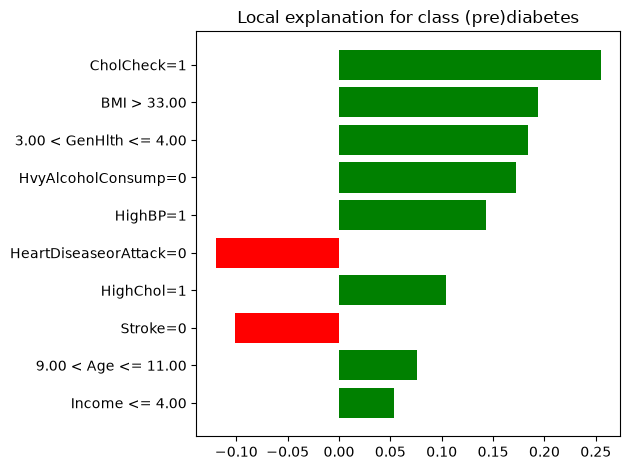

In [8]:
from lime.lime_tabular import LimeTabularExplainer

# Fortæl LIME, hvilke inputvariabler der kun har værdierne 0 og 1
categorical_features = [
    i for i, feature in enumerate(features)
    if X_train[feature].nunique(dropna=True) <= 2
]

lime_explainer = LimeTabularExplainer(
    training_data=X_train.to_numpy(dtype=float),
    feature_names=features,
    class_names=["No (pre)diabetes", "(pre)diabetes"],
    categorical_features=categorical_features,
    mode="classification",
    random_state=SEED
)

# Vælg én person fra testdata
row = explain_row.iloc[0]
print("LIME respondent index:", EXPLAIN_INDEX)

lime_explanation = lime_explainer.explain_instance(
    data_row=row.to_numpy(dtype=float),
    predict_fn=model.predict_proba,
    labels=(1,),
    num_features=10,
    num_samples=3000
)

# Vis hvilke variabler der påvirker forklaringen for klasse 1
print("Modelscore for (præ)diabetes:",
      round(model.predict_proba(row.to_frame().T)[0, 1], 3))
print(lime_explanation.as_list(label=1))

lime_explanation.as_pyplot_figure(label=1)
plt.tight_layout()
plt.show()

In [9]:
print("LIME local fidelity:", lime_explanation.score)

LIME local fidelity: 0.47851490025473986


## LIME stability over 20 random seeds

In [10]:
import copy
import numpy as np
import pandas as pd
import torch
from IPython.display import display

# Brug din eksisterende LIME-explainer:
base_explainer = lime_explainer  # Ret til lime_explainer, hvis det er navnet

# Samme respondent som tidligere.
# row_position er defineret tidligere i din notebook.
respondent = explain_row.iloc[0].to_numpy(dtype=float)

N_RUNS = 20
N_SAMPLES = 3000
N_FEATURES = 10  # Samme antal som i din viste LIME-figur
TOP_K = 5
POSITIVE_CLASS = 1

feature_names = X_train.columns.tolist()


# LIME sender rå featureværdier ind.
# Brug præcis samme preprocessing og trænede netværk.
def predict_for_lime(values):
    frame = pd.DataFrame(values, columns=feature_names)
    transformed = preprocess.transform(frame).astype("float32")

    net.eval()
    with torch.no_grad():
        logits = net(
            torch.from_numpy(transformed).to(device)
        ).reshape(-1)

        positive = torch.sigmoid(logits).cpu().numpy()

    return np.column_stack([1 - positive, positive])


model_score = float(
    predict_for_lime(respondent.reshape(1, -1))[0, POSITIVE_CLASS]
)

run_results = []
top_features = []
lime_explanations = {}

for seed in range(N_RUNS):
    # Bevar opsætningen fra den oprindelige forklaring.
    # Kopiering undgår at ændre din eksisterende explainer.
    current_explainer = copy.deepcopy(base_explainer)

    rng = np.random.RandomState(seed)
    current_explainer.random_state = rng

    if getattr(current_explainer, "discretizer", None) is not None:
        current_explainer.discretizer.random_state = rng

    explanation = current_explainer.explain_instance(
        data_row=respondent,
        predict_fn=predict_for_lime,
        labels=(POSITIVE_CLASS,),
        top_labels=None,
        num_features=N_FEATURES,
        num_samples=N_SAMPLES,
    )

    lime_explanations[seed] = explanation

    surrogate_score = float(
        np.asarray(explanation.local_pred).reshape(-1)[0]
    )

    run_results.append({
        "seed": seed,
        "local_fidelity": float(explanation.score),
        "NN_score": model_score,
        "LIME_score": surrogate_score,
        "absolute_local_error": abs(surrogate_score - model_score),
    })

    # Rangér efter størrelsen af bidraget, uanset fortegn.
    weights = explanation.as_map()[POSITIVE_CLASS]
    strongest = sorted(
        weights, key=lambda item: abs(item[1]), reverse=True
    )[:TOP_K]

    for feature_id, weight in strongest:
        top_features.append({
            "seed": seed,
            "feature": feature_names[feature_id],
            "weight": float(weight),
        })

    print(f"Kørsel {seed + 1}/{N_RUNS} færdig")


# 1. Resultater fra alle 20 kørsler
lime_runs = pd.DataFrame(run_results)

print(f"\nRespondentens position i testsættet: {row_position}")
print(f"Respondentens oprindelige indeks: {X_test.index[row_position]}")
print(f"NN-score: {model_score:.4f}")

display(lime_runs.round(4))


# 2. Samlet fidelity og fejl ved selve respondenten
lime_summary = (
    lime_runs[["local_fidelity", "absolute_local_error"]]
    .agg(["mean", "std", "min", "max"])
    .T
)

print("\nOpsummering af de 20 kørsler:")
display(lime_summary.round(4))


# 3. Stabilitet af de fem vigtigste features
top_features = pd.DataFrame(top_features)

feature_stability = (
    top_features.groupby("feature")
    .agg(
        top5_count=("seed", "nunique"),
        positive_count=("weight", lambda s: int((s > 0).sum())),
        negative_count=("weight", lambda s: int((s < 0).sum())),
    )
)

feature_stability["top5_frequency_pct"] = (
    100 * feature_stability["top5_count"] / N_RUNS
)

feature_stability = feature_stability.sort_values(
    ["top5_count", "feature"], ascending=[False, True]
)

print("\nHvor ofte er hver feature blandt de fem vigtigste?")
display(feature_stability.round(1))

Kørsel 1/20 færdig
Kørsel 2/20 færdig
Kørsel 3/20 færdig
Kørsel 4/20 færdig
Kørsel 5/20 færdig
Kørsel 6/20 færdig
Kørsel 7/20 færdig
Kørsel 8/20 færdig
Kørsel 9/20 færdig
Kørsel 10/20 færdig
Kørsel 11/20 færdig
Kørsel 12/20 færdig
Kørsel 13/20 færdig
Kørsel 14/20 færdig
Kørsel 15/20 færdig
Kørsel 16/20 færdig
Kørsel 17/20 færdig
Kørsel 18/20 færdig
Kørsel 19/20 færdig
Kørsel 20/20 færdig

Respondentens position i testsættet: 0
Respondentens oprindelige indeks: 57608
NN-score: 0.8854


,seed,local_fidelity,NN_score,LIME_score,absolute_local_error
0,0,0.4602,0.8854,1.0048,0.1194
1,1,0.4564,0.8854,1.0115,0.1261
2,2,0.4643,0.8854,0.9714,0.0860
3,3,0.4710,0.8854,1.0134,0.1280
4,4,0.4627,0.8854,1.0125,0.1270
5,5,0.4631,0.8854,1.0108,0.1253
6,6,0.4721,0.8854,1.0267,0.1413
7,7,0.4900,0.8854,1.0329,0.1475
8,8,0.4567,0.8854,1.0103,0.1249
9,9,0.4763,0.8854,1.0111,0.1257



Opsummering af de 20 kørsler:


,mean,std,min,max
local_fidelity,0.4654,0.0122,0.4483,0.4900
absolute_local_error,0.1231,0.0141,0.0860,0.1475



Hvor ofte er hver feature blandt de fem vigtigste?


,top5_count,positive_count,negative_count,top5_frequency_pct
feature,,,,
BMI,20,20,0,100.0
CholCheck,20,20,0,100.0
GenHlth,20,20,0,100.0
HvyAlcoholConsump,20,20,0,100.0
HighBP,18,18,0,90.0
HighChol,2,2,0,10.0


## Kernel SHAP: global feature contributions

In [ ]:
import shap

# Et lille udsnit af træningsdata bruges som sammenligningsgrundlag
background = X_train.sample(
    n=min(50, len(X_train)),
    random_state=SEED
)

# Forklar op til 40 testpersoner
X_shap = X_test.sample(
    n=min(40, len(X_test)),
    random_state=SEED
)

shap_explainer = shap.KernelExplainer(
    model.predict_proba,
    background
)

# Seed coalition sampling independently of earlier cells.
np.random.seed(SEED)
shap_values = shap_explainer.shap_values(
    X_shap,
    nsamples=200
)

# Udtræk SHAP-værdier for klasse 1: (præ)diabetes
# SHAP-versioner kan returnere værdierne i lidt forskellige formater.
if isinstance(shap_values, list):
    shap_positive = shap_values[1]
else:
    shap_values = np.asarray(shap_values)
    shap_positive = shap_values[:, :, 1] if shap_values.ndim == 3 else shap_values

# Samlet oversigt: hvilke variabler betyder mest på tværs af personerne?
shap.summary_plot(
    shap_positive,
    X_shap,
    feature_names=features,
    plot_type="bar"
)

  0%|          | 0/1 [00:00<?, ?it/s]c:\Users\vict7\miniforge3\envs\forklarbar-fixed\Lib\site-packages\sklearn\utils\validation.py:2830: UserWarning: X does not have valid feature names, but SimpleImputer was fitted with feature names
  warnings.warn(
c:\Users\vict7\miniforge3\envs\forklarbar-fixed\Lib\site-packages\sklearn\utils\validation.py:2830: UserWarning: X does not have valid feature names, but SimpleImputer was fitted with feature names
  warnings.warn(
100%|██████████| 1/1 [00:00<00:00, 52.14it/s]


SHAP respondent index: 57608
Model score: 0.8854317665100098
True survey label: 1
SHAP base + contributions: 0.8854317665100098


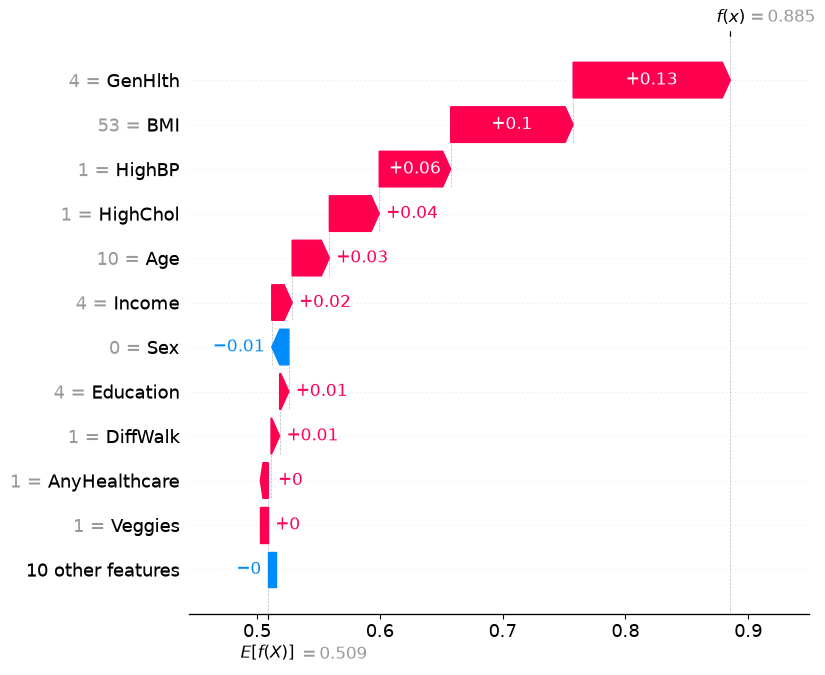

,Feature,Raw value,SHAP contribution (class 1)
0,HighBP,1.0,0.058207
1,HighChol,1.0,0.040616
2,CholCheck,1.0,0.000000
3,BMI,53.0,0.099715
4,Smoker,0.0,0.000000
5,Stroke,0.0,0.000000
6,HeartDiseaseorAttack,0.0,0.000000
7,PhysActivity,0.0,0.000000
8,Fruits,0.0,0.000000
9,Veggies,1.0,0.000000


In [12]:
# Explain the selected person separately from the global random sample.
# This keeps the global summary based on its original random 40-person sample.
np.random.seed(SEED)
selected_shap_values = shap_explainer.shap_values(explain_row, nsamples=200)
if isinstance(selected_shap_values, list):
    selected_positive = np.asarray(selected_shap_values[1])[0]
else:
    selected_array = np.asarray(selected_shap_values)
    selected_positive = (selected_array[0, :, 1]
                         if selected_array.ndim == 3 else selected_array[0])

expected = np.asarray(shap_explainer.expected_value).reshape(-1)
base_value = float(expected[1] if len(expected) > 1 else expected[0])
local_shap = shap.Explanation(
    values=selected_positive,
    base_values=base_value,
    data=explain_row.iloc[0].to_numpy(),
    feature_names=features
)
print("SHAP respondent index:", EXPLAIN_INDEX)
print("Model score:", float(model.predict_proba(explain_row)[0, 1]))
print("True survey label:", int(y_test.loc[EXPLAIN_INDEX]))
print("SHAP base + contributions:", base_value + selected_positive.sum())
shap.plots.waterfall(local_shap, max_display=12)
display(pd.DataFrame({
    "Feature": features,
    "Raw value": explain_row.iloc[0].to_numpy(),
    "SHAP contribution (class 1)": selected_positive
}))


## Export reproducible evidence

These files contain the results of the current run, not hard-coded report values. Test predictions include original row indices so comparisons can be paired correctly. Runtime versions and the dataset hash are recorded alongside the outputs. Run both notebooks before comparing predictions.


In [ ]:
import hashlib
import json
import platform
from importlib.metadata import version

output_dir = Path("results/nn")
output_dir.mkdir(parents=True, exist_ok=True)
pd.DataFrame({
    "dataset_index": X_test.index,
    "actual": y_test.to_numpy(),
    "score": probabilities,
    "predicted": (probabilities >= 0.5).astype(int),
}).to_csv(output_dir / "test_predictions.csv", index=False)
explain_row.to_csv(output_dir / "patient_raw.csv", index_label="dataset_index")
pd.DataFrame({"feature": features, "mean_abs_shap": np.abs(shap_positive).mean(axis=0)}).sort_values(
    "mean_abs_shap", ascending=False
).to_csv(output_dir / "global_shap.csv", index=False)
pd.DataFrame({"feature": features, "raw_value": explain_row.iloc[0].to_numpy(),
              "shap_contribution": selected_positive}).to_csv(output_dir / "patient_shap.csv", index=False)
pd.DataFrame(lime_explanation.as_list(label=1), columns=["condition", "weight"]).to_csv(
    output_dir / "patient_lime.csv", index=False)
metadata = {
    "model": "nn", "seed": SEED, "patient_index": EXPLAIN_INDEX,
    "dataset_sha256": hashlib.sha256(DATA_PATH.read_bytes()).hexdigest(),
    "python": platform.python_version(),
    "versions": {package: version(package) for package in
                 ["numpy", "pandas", "scikit-learn", "scipy", "matplotlib", "lime", "shap"]},
    "accuracy": float(np.mean((probabilities >= 0.5) == y_test.to_numpy())),
    "roc_auc": float(roc_auc_score(y_test, probabilities)),
    "patient_score": float(model.predict_proba(explain_row)[0, 1]),
    "lime_weighted_r2": float(lime_explanation.score),
    "shap_baseline": base_value,
    "shap_reconstruction_error": float(abs(base_value + selected_positive.sum()
                                          - model.predict_proba(explain_row)[0, 1])),
}
metadata["versions"]["torch"] = version("torch")
metadata["device"] = str(device)
lime_runs.to_csv(output_dir / "lime_runs.csv", index=False)
feature_stability.to_csv(output_dir / "lime_stability.csv")
(output_dir / "run_metadata.json").write_text(json.dumps(metadata, indent=2) + "\n")
print("Saved current-run evidence to", output_dir.resolve())
